In [19]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use a local copy when available; otherwise load the public source dataset.
data_path = next(
    (folder / "data" / "hotels.csv"
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "hotels.csv").is_file()),
    None,
)
data_url = (
    "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/"
    "data/2020/2020-02-11/hotels.csv"
)
df = pd.read_csv(data_path if data_path is not None else data_url)

print(df)

               hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27   
2                    July     

# Hotel Booking Data Preparation

## Dataset Verification

In [20]:
raw = df.copy()

In [21]:
raw.shape

(119390, 32)

In [22]:
raw.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [23]:
raw['hotel'].value_counts()

,count
hotel,
City Hotel,79330
Resort Hotel,40060


In [24]:
# Checking the cancellation labels in the dataset
raw['is_canceled'].value_counts(dropna=False)

,count
is_canceled,
0,75166
1,44224


In [25]:
year = df["arrival_date_year"].astype(str)
month = df["arrival_date_month"]
day = df["arrival_date_day_of_month"].astype(str)

arrival_date_text = year + "-" + month + "-" + day

df["arrival_date"] = pd.to_datetime(
    arrival_date_text,
    format="%Y-%B-%d"
)

print(df["arrival_date"].min())
print(df['arrival_date'].max())

2015-07-01 00:00:00
2017-08-31 00:00:00


In [26]:
df["arrival_date"].isna().sum()

np.int64(0)

## Data Understanding and EDA

### Data Types and Missing Values

In [27]:
df.shape

(119390, 33)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   hotel                           119390 non-null  object        
 1   is_canceled                     119390 non-null  int64         
 2   lead_time                       119390 non-null  int64         
 3   arrival_date_year               119390 non-null  int64         
 4   arrival_date_month              119390 non-null  object        
 5   arrival_date_week_number        119390 non-null  int64         
 6   arrival_date_day_of_month       119390 non-null  int64         
 7   stays_in_weekend_nights         119390 non-null  int64         
 8   stays_in_week_nights            119390 non-null  int64         
 9   adults                          119390 non-null  int64         
 10  children                        119386 non-null  float64

In [29]:
# Count missing values in each column
missing_values = df.isna().sum()
missing_values = missing_values[missing_values > 0]

missing_values

,0
children,4
country,488
agent,16340
company,112593


In [30]:
# Missing values pct
missing_values_pct = missing_values / len(df) * 100
missing_values_pct

,0
children,0.003350
country,0.408744
agent,13.686238
company,94.306893


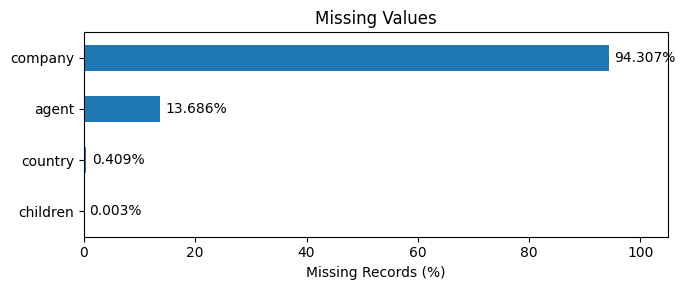

In [31]:
# Show missing percentages directly on the bars
ax = missing_values_pct.sort_values().plot.barh(figsize=(7, 3))
ax.bar_label(ax.containers[0], fmt='%.3f%%', padding=4)
plt.title('Missing Values')
plt.xlabel('Missing Records (%)')
plt.ylabel('')
plt.xlim(0, 105)
plt.tight_layout()
plt.show()


### Derived Columns


In [32]:
# Total number of nights booked
df['nights'] = (
    df['stays_in_weekend_nights']
    + df['stays_in_week_nights']
)


In [33]:
# Month number for seasonal analysis
df['arrival_month'] = df['arrival_date'].dt.month


In [34]:
# Check the new columns
df[['hotel', 'arrival_date', 'nights', 'arrival_month']].head()


,hotel,arrival_date,nights,arrival_month
0,Resort Hotel,2015-07-01,0,7
1,Resort Hotel,2015-07-01,0,7
2,Resort Hotel,2015-07-01,1,7
3,Resort Hotel,2015-07-01,1,7
4,Resort Hotel,2015-07-01,2,7


In [35]:
print('Original:', raw.shape)
print('Working:', df.shape)


Original: (119390, 32)
Working: (119390, 35)


## Data Split

In [36]:
# Find the project folder and load the client's scoring contract
import sys
from pathlib import Path
path = next((f / p for f in (Path.cwd(), *Path.cwd().parents)
             for p in ('src/contract.py', 'contract.py') if (f / p).is_file()), None)
# Colab may have only the notebook, so download the project if needed.
if path is None:
    import subprocess
    project = Path.cwd() / 'Build-Week-2-Hotel-overbooking-forecast'
    if not project.exists():
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/MohitPasupuleti/Build-Week-2-Hotel-overbooking-forecast.git',
                        str(project)], check=True)
    path = project / 'src/contract.py'

ROOT = path.parent.parent if path.parent.name == 'src' else path.parent
sys.path.insert(0, str(path.parent))
import contract
print('Project folder:', ROOT)

Project folder: /content/Build-Week-2-Hotel-overbooking-forecast


In [37]:
# Split by arrival date using the contract: train, validation (choose), test (proof)
train_bookings, validation_bookings, test_bookings = (x.copy() for x in contract.split_periods(df))

In [38]:
# Check the number of bookings in each period
print('Train:', len(train_bookings))
print('Validation:', len(validation_bookings))
print('Test:', len(test_bookings))
print('Total: ', len(train_bookings) + len(validation_bookings) + len(test_bookings))


Train: 49157
Validation: 29546
Test: 40687
Total:  119390


In [39]:
# Check that every booking is included in a split
total_bookings = (
    len(train_bookings)
    + len(validation_bookings)
    + len(test_bookings)
)

assert total_bookings == len(df)


## Cancellation Patterns

### Bookings and Cancellation Rates by Hotel

In [40]:
# Count bookings, cancellations and the cancellation rate by hotel
hotel_summary = train_bookings.groupby('hotel')['is_canceled'].agg(
    ['count', 'sum', 'mean']
)


In [41]:
hotel_summary = hotel_summary.rename(columns={
    'count': 'bookings',
    'sum': 'cancellations',
    'mean': 'cancellation_rate'
})


hotel_summary['cancellation_rate_pct'] = hotel_summary['cancellation_rate'] * 100
hotel_summary[['bookings', 'cancellations', 'cancellation_rate_pct']].round(2)


,bookings,cancellations,cancellation_rate_pct
hotel,,,
City Hotel,31623,13175,41.66
Resort Hotel,17534,4410,25.15


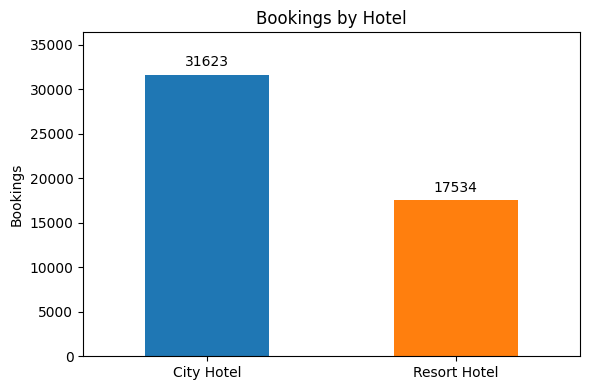

In [42]:
# Show how many training bookings each hotel has
ax = hotel_summary['bookings'].plot.bar(figsize=(6, 4), rot=0, color=['tab:blue', 'tab:orange'])
ax.bar_label(ax.containers[0], fmt='%.0f', padding=4)
plt.title('Bookings by Hotel')
plt.xlabel('')
plt.ylabel('Bookings')
plt.ylim(0, hotel_summary['bookings'].max() * 1.15)
plt.tight_layout()
plt.show()


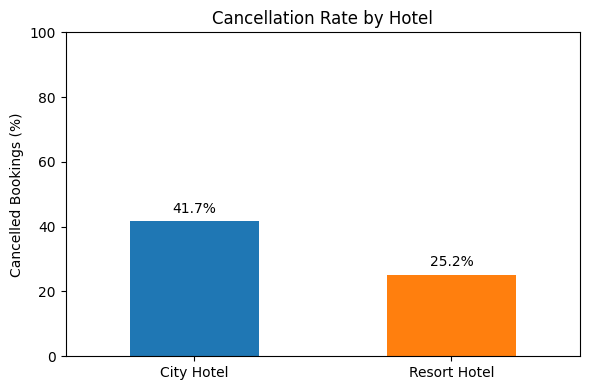

In [43]:
# Show the percentage cancelled at each hotel
ax = hotel_summary['cancellation_rate_pct'].plot.bar(figsize=(6, 4), rot=0, color=['tab:blue', 'tab:orange'])
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=4)
plt.title('Cancellation Rate by Hotel')
plt.xlabel('')
plt.ylabel('Cancelled Bookings (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Training Data Summary

In [44]:
# Check missing values in the training period
training_missing = train_bookings.isna().sum()
training_missing[training_missing > 0]


,0
children,4
country,284
agent,6960
company,46123


In [45]:
# Inspect numerical values
train_bookings.describe().T

,count,mean,min,25%,50%,75%,max,std
is_canceled,49157.0,0.357731,0.0,0.0,0.0,1.0,1.0,0.479337
lead_time,49157.0,88.859735,0.0,12.0,56.0,131.0,737.0,95.769441
arrival_date_year,49157.0,2015.552536,2015.0,2015.0,2016.0,2016.0,2016.0,0.497237
arrival_date_week_number,49157.0,26.516122,1.0,15.0,25.0,38.0,53.0,13.636283
arrival_date_day_of_month,49157.0,15.953354,1.0,8.0,16.0,24.0,31.0,8.676579
stays_in_weekend_nights,49157.0,0.875074,0.0,0.0,1.0,2.0,18.0,0.987737
stays_in_week_nights,49157.0,2.391297,0.0,1.0,2.0,3.0,42.0,1.859477
adults,49157.0,1.815021,0.0,2.0,2.0,2.0,55.0,0.678641
children,49153.0,0.071613,0.0,0.0,0.0,0.0,10.0,0.338078
babies,49157.0,0.008219,0.0,0.0,0.0,0.0,10.0,0.107936


In [46]:
# Inspect categorical values and their coverage
train_bookings.select_dtypes(include=['object', 'string', 'category']).describe().T

,count,unique,top,freq
hotel,49157,2,City Hotel,31623
arrival_date_month,49157,12,May,5478
meal,49157,5,BB,38764
country,48873,139,PRT,25689
market_segment,49157,8,Online TA,17873
distribution_channel,49157,5,TA/TO,39824
reserved_room_type,49157,10,A,37987
assigned_room_type,49157,12,A,31230
deposit_type,49157,3,No Deposit,41548
customer_type,49157,4,Transient,31747


### Cancellation Distribution

The final training class counts and plot are shown after feature preparation under Class Distribution Analysis.


### Bookings and Cancellation Rates by Arrival Month

In [47]:
# Summarise each hotel and month
monthly_summary = train_bookings.groupby(['arrival_month', 'hotel'])['is_canceled'].agg(['count', 'mean'])
monthly_summary = monthly_summary.rename(columns={'count': 'bookings', 'mean': 'cancellation_rate'})
monthly_summary['cancellation_rate_pct'] = monthly_summary['cancellation_rate'] * 100
monthly_summary[['bookings', 'cancellation_rate_pct']].round(2)

bookings  cancellation_rate_pct
arrival_month hotel                                        
1             City Hotel        1364                  32.11
              Resort Hotel       884                  13.46
2             City Hotel        2371                  39.22
              Resort Hotel      1520                  26.78
3             City Hotel        3046                  36.38
              Resort Hotel      1778                  20.75
4             City Hotel        3561                  43.22
              Resort Hotel      1867                  27.96
5             City Hotel        3676                  39.06
              Resort Hotel      1802                  26.58
6             City Hotel        3923                  43.84
              Resort Hotel      1369                  27.47
7             City Hotel        1398                  67.17
              Resort Hotel      1378                  23.22
8             City Hotel        2480                  49.68
              Resort Hotel      1409                  25.98
9             City Hotel        3529                  43.72
              Resort Hotel      1585                  34.76
10            City Hotel        3386                  39.01
              Resort Hotel      1571                  26.16
11            City Hotel        1235                  24.37
              Resort Hotel      1105                  16.74
12            City Hotel        1654                  40.39
              Resort Hotel      1266                  24.09

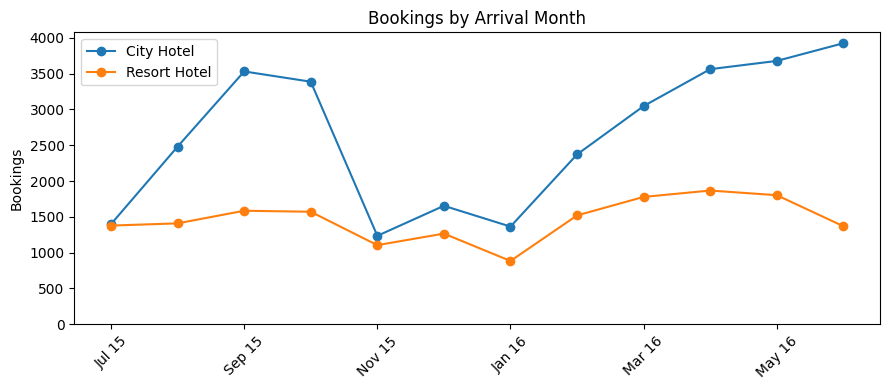

In [48]:
# Show the training months in date order, from July 2015 to June 2016
month_order = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
month_labels = ['Jul 15', 'Aug 15', 'Sep 15', 'Oct 15', 'Nov 15', 'Dec 15',
                'Jan 16', 'Feb 16', 'Mar 16', 'Apr 16', 'May 16', 'Jun 16']

monthly_bookings_plot = monthly_summary['bookings'].unstack('hotel').reindex(month_order)
monthly_bookings_plot.index = month_labels
monthly_bookings_plot.plot(figsize=(9, 4), marker='o', rot=45)
plt.title('Bookings by Arrival Month')
plt.xlabel('')
plt.ylabel('Bookings')
plt.ylim(bottom=0)
plt.legend(title='')
plt.tight_layout()
plt.show()


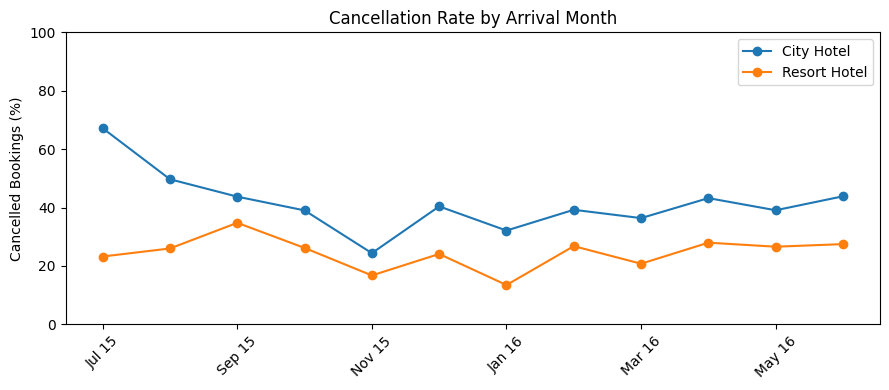

In [49]:
# Plotting the cancellation rate
monthly_rates_plot = monthly_summary['cancellation_rate_pct'].unstack('hotel').reindex(month_order)
monthly_rates_plot.index = month_labels
monthly_rates_plot.plot(figsize=(9, 4), marker='o', rot=45)
plt.title('Cancellation Rate by Arrival Month')
plt.xlabel('')
plt.ylabel('Cancelled Bookings (%)')
plt.ylim(0, 100)
plt.legend(title='')
plt.tight_layout()
plt.show()


### Bookings and Cancellation Rates by Market Segment

In [50]:
# Compare booking channels across the two hotels
segment_summary = train_bookings.groupby(['market_segment', 'hotel'])['is_canceled'].agg(['count', 'sum', 'mean'])
segment_summary = segment_summary.rename(columns={'count': 'bookings', 'sum': 'cancellations', 'mean': 'cancellation_rate'})
segment_summary['cancellation_rate_pct'] = segment_summary['cancellation_rate'] * 100
segment_summary[['bookings', 'cancellations', 'cancellation_rate_pct']].round(2)

bookings  cancellations  cancellation_rate_pct
market_segment hotel                                                       
Aviation       City Hotel          64             15                  23.44
Complementary  City Hotel         261             28                  10.73
               Resort Hotel        77              8                  10.39
Corporate      City Hotel        1525            316                  20.72
               Resort Hotel      1187            156                  13.14
Direct         City Hotel        2209            370                  16.75
               Resort Hotel      2792            318                  11.39
Groups         City Hotel        7363           4906                  66.63
               Resort Hotel      3026           1520                  50.23
Offline TA/TO  City Hotel        8798           3967                  45.09
               Resort Hotel      3980            587                  14.75
Online TA      City Hotel       11401           3571                  31.32
               Resort Hotel      6472           1821                  28.14
Undefined      City Hotel           2              2                 100.00

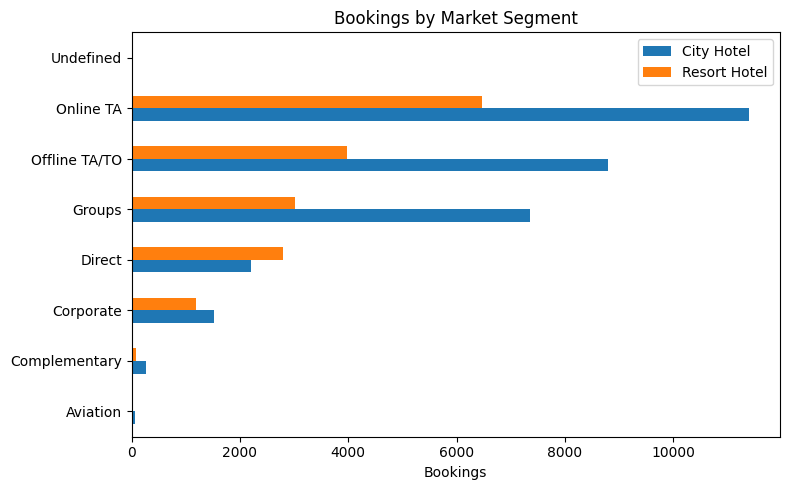

In [51]:
# Comparing channel bookings
segment_summary['bookings'].unstack('hotel').plot.barh(figsize=(8, 5))
plt.title('Bookings by Market Segment')
plt.xlabel('Bookings')
plt.ylabel('')
plt.legend(title='')
plt.tight_layout()
plt.show()


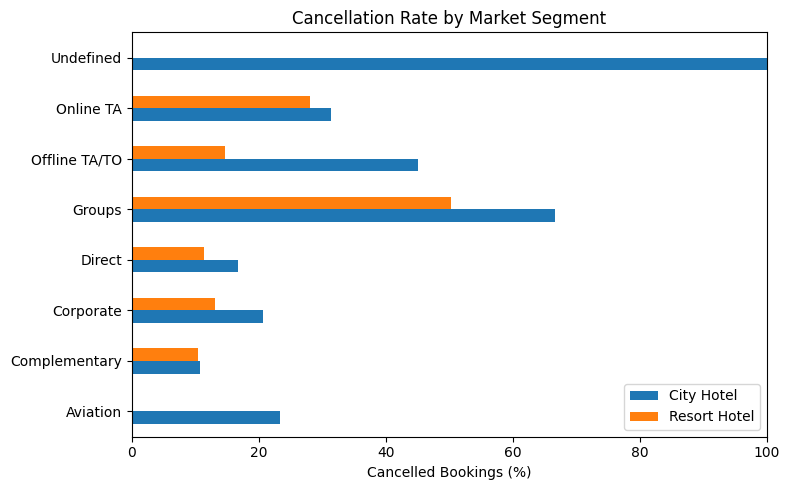

In [52]:
# Compare the percentage cancelled in each channel
segment_summary['cancellation_rate_pct'].unstack('hotel').plot.barh(figsize=(8, 5))
plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Cancelled Bookings (%)')
plt.ylabel('')
plt.xlim(0, 100)
plt.legend(title='')
plt.tight_layout()
plt.show()


### Bookings and Cancellation Rates by Deposit Type

In [53]:
# Compare deposit categories across hotels
deposit_summary = train_bookings.groupby(['deposit_type', 'hotel'])['is_canceled'].agg(['count', 'sum', 'mean'])
deposit_summary = deposit_summary.rename(columns={'count': 'bookings', 'sum': 'cancellations', 'mean': 'cancellation_rate'})
deposit_summary['cancellation_rate_pct'] = deposit_summary['cancellation_rate'] * 100
deposit_summary[['bookings', 'cancellations', 'cancellation_rate_pct']].round(2)

bookings  cancellations  cancellation_rate_pct
deposit_type hotel                                                       
No Deposit   City Hotel       25275           6847                  27.09
             Resort Hotel     16273           3309                  20.33
Non Refund   City Hotel        6343           6328                  99.76
             Resort Hotel      1151           1093                  94.96
Refundable   City Hotel           5              0                   0.00
             Resort Hotel       110              8                   7.27

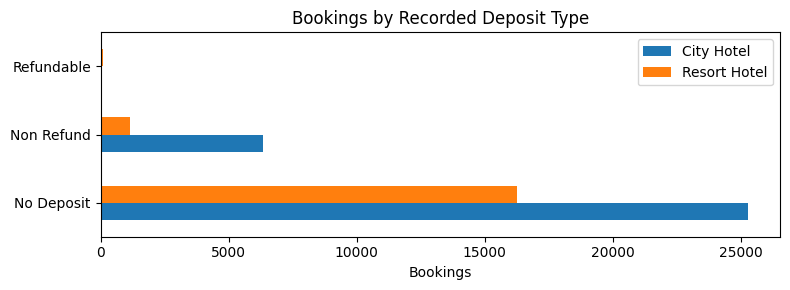

In [54]:
deposit_summary['bookings'].unstack('hotel').plot.barh(figsize=(8, 3))
plt.title('Bookings by Recorded Deposit Type')
plt.xlabel('Bookings')
plt.ylabel('')
plt.legend(title='')
plt.tight_layout()
plt.show()


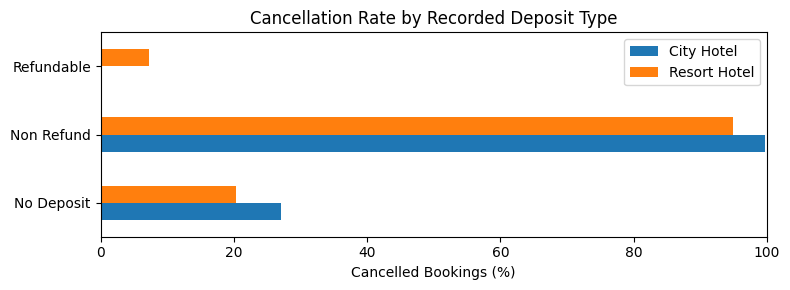

In [55]:
deposit_summary['cancellation_rate_pct'].unstack('hotel').plot.barh(figsize=(8, 3))
plt.title('Cancellation Rate by Recorded Deposit Type')
plt.xlabel('Cancelled Bookings (%)')
plt.ylabel('')
plt.xlim(0, 100)
plt.legend(title='')
plt.tight_layout()
plt.show()


### Lead Time and Cancellations

In [56]:
# plotting groups in a separate copy
lead_time_analysis = train_bookings[['hotel', 'lead_time', 'is_canceled']].copy()
lead_time_analysis['lead_time_group'] = pd.cut(
    lead_time_analysis['lead_time'],
    bins=[-1, 0, 7, 30, 90, 180, float('inf')],
    labels=['0 days', '1–7 days', '8–30 days', '31–90 days', '91–180 days', '181+ days']
)
lead_time_analysis['lead_time_group'].isna().sum()

np.int64(0)

In [57]:
# Include group counts so small samples remain visible
lead_time_summary = lead_time_analysis.groupby(['lead_time_group', 'hotel'], observed=True)['is_canceled'].agg(['count', 'mean'])
lead_time_summary = lead_time_summary.rename(columns={'count': 'bookings', 'mean': 'cancellation_rate'})
lead_time_summary['cancellation_rate_pct'] = lead_time_summary['cancellation_rate'] * 100
lead_time_summary[['bookings', 'cancellation_rate_pct']].round(2)

bookings  cancellation_rate_pct
lead_time_group hotel                                        
0 days          City Hotel        1634                   9.24
                Resort Hotel      1704                   3.76
1–7 days        City Hotel        3923                  14.99
                Resort Hotel      2662                   7.40
8–30 days       City Hotel        5374                  30.44
                Resort Hotel      2796                  18.53
31–90 days      City Hotel        8933                  38.04
                Resort Hotel      4323                  30.42
91–180 days     City Hotel        6043                  50.41
                Resort Hotel      3510                  35.70
181+ days       City Hotel        5716                  76.21
                Resort Hotel      2539                  41.87

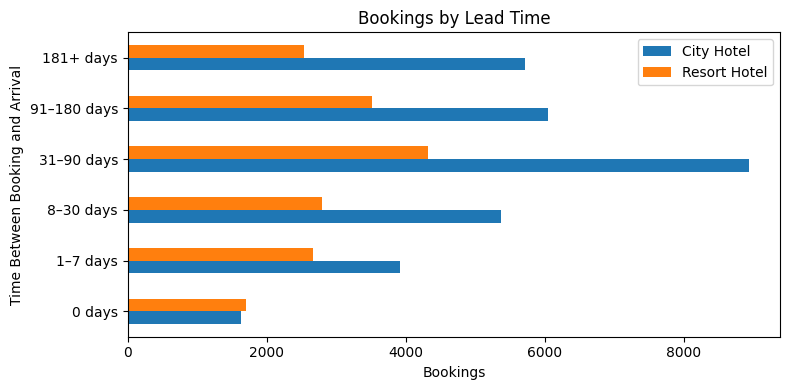

In [58]:
# Compare booking counts with created bins to identify where most bookings are made in advance
lead_time_summary['bookings'].unstack('hotel').plot.barh(figsize=(8, 4))
plt.title('Bookings by Lead Time')
plt.xlabel('Bookings')
plt.ylabel('Time Between Booking and Arrival')
plt.legend(title='')
plt.tight_layout()
plt.show()


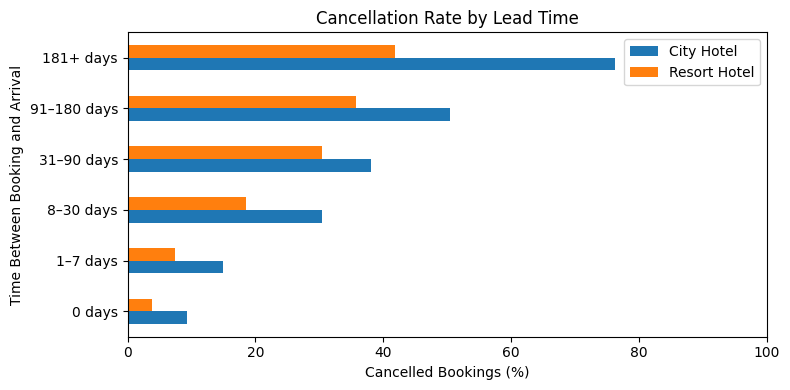

In [59]:
# Compare cancellation rates with created bins to identify where most cancellations occur in advance
lead_time_summary['cancellation_rate_pct'].unstack('hotel').plot.barh(figsize=(8, 4))
plt.title('Cancellation Rate by Lead Time')
plt.xlabel('Cancelled Bookings (%)')
plt.ylabel('Time Between Booking and Arrival')
plt.xlim(0, 100)
plt.legend(title='')
plt.tight_layout()
plt.show()


### Bookings and Cancellations by Arrival Night

In [60]:
# Create the observed hotel-night table
nightly_summary = train_bookings.groupby(['arrival_date', 'hotel'])['is_canceled'].agg(['count', 'sum'])
nightly_summary = nightly_summary.rename(columns={'count': 'bookings', 'sum': 'cancellations'})
nightly_summary['non_cancelled_bookings'] = nightly_summary['bookings'] - nightly_summary['cancellations']
nightly_summary.head(6)

bookings  cancellations  non_cancelled_bookings
arrival_date hotel                                                        
2015-07-01   City Hotel          79             14                      65
             Resort Hotel        43              5                      38
2015-07-02   City Hotel          49             48                       1
             Resort Hotel        44              9                      35
2015-07-03   City Hotel          16              6                      10
             Resort Hotel        40             13                      27

In [61]:
# Check hotel-night totals against the training bookings
assert nightly_summary['bookings'].sum() == len(train_bookings)
assert nightly_summary['cancellations'].sum() == train_bookings['is_canceled'].sum()
print('Hotel-nights:', len(nightly_summary))
nightly_summary.groupby('hotel').agg(['mean', 'max']).round(2)

Hotel-nights: 732


bookings      cancellations      non_cancelled_bookings     
                 mean  max          mean  max                   mean  max
hotel                                                                    
City Hotel      86.40  340         36.00  221                  50.40  204
Resort Hotel    47.91  222         12.05  106                  35.86  116

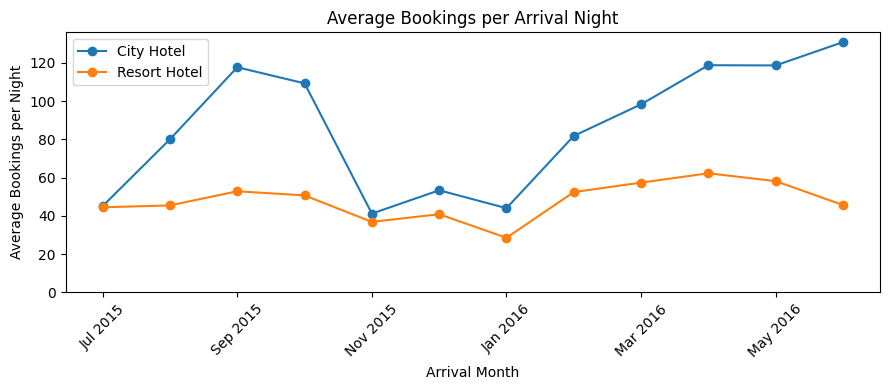

In [62]:
# Average nightly booking counts within each month to simplify the daily trend
monthly_nightly_bookings = nightly_summary['bookings'].unstack('hotel').resample('MS').mean()
monthly_nightly_bookings.index = monthly_nightly_bookings.index.strftime('%b %Y')
monthly_nightly_bookings.plot(figsize=(9, 4), marker='o', rot=45)
plt.title('Average Bookings per Arrival Night')
plt.xlabel('Arrival Month')
plt.ylabel('Average Bookings per Night')
plt.ylim(bottom=0)
plt.legend(title='')
plt.tight_layout()
plt.show()


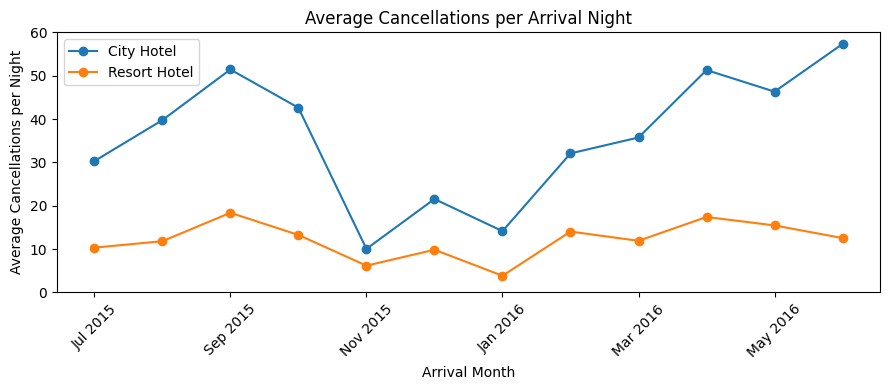

In [63]:
# Average nightly cancellation counts within the same months
monthly_nightly_cancellations = nightly_summary['cancellations'].unstack('hotel').resample('MS').mean()
monthly_nightly_cancellations.index = monthly_nightly_cancellations.index.strftime('%b %Y')
monthly_nightly_cancellations.plot(figsize=(9, 4), marker='o', rot=45)
plt.title('Average Cancellations per Arrival Night')
plt.xlabel('Arrival Month')
plt.ylabel('Average Cancellations per Night')
plt.ylim(bottom=0)
plt.legend(title='')
plt.tight_layout()
plt.show()


### Investigating the Client Observations

#### Why do non-refundable bookings cancel so often?

The training data supports what the finance team noticed. Around **99.76% of non-refundable bookings at City Hotel** and **94.96% at Resort Hotel** were cancelled.

Non-refundable does not mean the guest will definitely arrive. A guest can cancel even if they lose the payment.


#### Why was the cancellation list not useful to the front desk?

The list showed which bookings were most likely to cancel. But the front desk needed to know **how many extra rooms they could safely sell for each night**.

The list did not directly answer that question. We need to turn cancellation probabilities into a nightly recommendation, with a safety buffer.

This could explain why the list was not useful, but we do not have enough information to confirm why the staff stopped using it.

#### Why did 95% accuracy not work well in practice?

Accuracy only tells us how often the model predicted the correct cancellation label. It does not tell us whether the hotel saved money or avoided walking guests.

We cannot confirm what went wrong with the vendor's model. We would need to check its features, data split, and evaluation method. Our final evaluation will therefore include **cost, empty rooms, and walks per 1,000 arrivals**, rather than accuracy alone.


In [64]:
# Check the non-refundable observation using the original training bookings
non_refund_summary = deposit_summary.xs('Non Refund', level='deposit_type')
non_refund_summary[['bookings', 'cancellations', 'cancellation_rate_pct']].round(2)

,bookings,cancellations,cancellation_rate_pct
hotel,,,
City Hotel,6343,6328,99.76
Resort Hotel,1151,1093,94.96


In [65]:
# Comparing the vendor claim with a reference
majority_accuracy_pct = train_bookings['is_canceled'].value_counts(normalize=True).max() * 100
print('Always predict the majority class: {:.2f}% training accuracy'.format(majority_accuracy_pct))

Always predict the majority class: 64.23% training accuracy


## Data Cleaning

### Original Training Records

Use the original columns for the audit so the counts stay the same if the cleaning cells are rerun. The split tables keep the original row index.

In [66]:
# Get the original records for the training period
training_source = raw.loc[train_bookings.index].copy()
training_source.shape

(49157, 32)

### Repeated Records

Identical published rows may be separate bookings. Since there are no distinct booking IDs, this is being retained instead of dropped.

In [67]:
# Count repeated rows beyond the first occurrence
repeated_rows = training_source.duplicated()
print('Repeated rows:', repeated_rows.sum())

Repeated rows: 16291


In [68]:
# Check which booking channels have repeated records
training_source.loc[repeated_rows, 'market_segment'].value_counts()

,count
market_segment,
Groups,8047
Offline TA/TO,5964
Online TA,1273
Corporate,654
Direct,327
Complementary,23
Aviation,3


In [69]:
training_source.loc[repeated_rows].head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
219,Resort Hotel,1,1,2015,July,28,8,0,1,2,...,No Deposit,NaN,110.0,0,Transient,104.72,0,1,Canceled,2015-07-08
256,Resort Hotel,0,91,2015,July,28,10,0,2,2,...,No Deposit,240.0,NaN,0,Transient,73.80,0,1,Check-Out,2015-07-12
261,Resort Hotel,0,30,2015,July,28,10,2,2,2,...,No Deposit,NaN,NaN,0,Transient-Party,197.00,0,1,Check-Out,2015-07-14
353,Resort Hotel,0,98,2015,July,29,13,1,1,2,...,No Deposit,240.0,NaN,0,Transient-Party,82.00,0,3,Check-Out,2015-07-15
372,Resort Hotel,0,40,2015,July,29,13,1,4,2,...,No Deposit,250.0,NaN,0,Transient,120.00,0,2,Check-Out,2015-07-18


### Missing Values

In [70]:
# Check missing values in the original training records
training_missing = training_source.isna().sum()
training_missing[training_missing > 0]

,0
children,4
country,284
agent,6960
company,46123


In [71]:
# Filling the children column with the median value from the training period
children_median = training_source['children'].median()
print('Training median for children:', children_median)

Training median for children: 0.0


### Unusual Values

In [72]:
# Calculating totals duration of stay and guests
training_nights = training_source['stays_in_weekend_nights'] + training_source['stays_in_week_nights']
training_guests = training_source['adults'] + training_source['children'] + training_source['babies']

In [73]:
# Keep quality flags separate from the model inputs
quality_flags = pd.DataFrame(index=training_source.index)
quality_flags['Zero guests'] = training_guests == 0
quality_flags['Unknown guest total'] = training_guests.isna()
quality_flags['Zero nights'] = training_nights == 0
quality_flags['Negative ADR'] = training_source['adr'] < 0
quality_flags['Zero ADR'] = training_source['adr'] == 0
quality_flags['ADR above 1000'] = training_source['adr'] > 1000
quality_flags['Guests above 10'] = training_guests > 10
quality_flags['Nights above 30'] = training_nights > 30
quality_flags.sum()

,0
Zero guests,49
Unknown guest total,4
Zero nights,371
Negative ADR,0
Zero ADR,1065
ADR above 1000,1
Guests above 10,14
Nights above 30,9


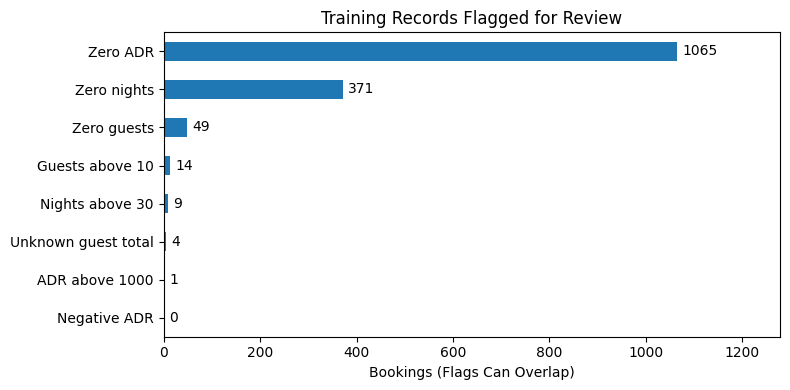

In [74]:
# Show how many training bookings need review
ax = quality_flags.sum().sort_values().plot.barh(figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt='%.0f', padding=4)
plt.title('Training Records Flagged for Review')
plt.xlabel('Bookings (Flags Can Overlap)')
plt.ylabel('')
plt.xlim(0, quality_flags.sum().max() * 1.2)
plt.tight_layout()
plt.show()

In [75]:
# Check for records with 0 guests
training_source.loc[quality_flags['Zero guests'],
    ['hotel', 'adults', 'children', 'babies', 'adr', 'market_segment']].head(10)

,hotel,adults,children,babies,adr,market_segment
2224,Resort Hotel,0,0.0,0,0.0,Corporate
2409,Resort Hotel,0,0.0,0,0.0,Corporate
3181,Resort Hotel,0,0.0,0,0.0,Groups
3684,Resort Hotel,0,0.0,0,0.0,Groups
3708,Resort Hotel,0,0.0,0,0.0,Groups
4127,Resort Hotel,0,0.0,0,0.0,Offline TA/TO
40392,City Hotel,0,0.0,0,0.0,Groups
40922,City Hotel,0,0.0,0,0.0,Online TA
41020,City Hotel,0,0.0,0,0.0,Online TA
41056,City Hotel,0,0.0,0,0.0,Online TA


In [76]:
# Check whether zero-night bookings also have zero prices
zero_night_records = training_source.loc[quality_flags['Zero nights']]
print('Zero-night bookings:', len(zero_night_records))
print('Zero-night bookings with zero ADR:', (zero_night_records['adr'] == 0).sum())

Zero-night bookings: 371
Zero-night bookings with zero ADR: 371


In [77]:
# Inspecting outliers
extreme_records = quality_flags['ADR above 1000'] | quality_flags['Guests above 10']
training_source.loc[extreme_records,
    ['hotel', 'adults', 'children', 'babies', 'adr', 'market_segment']]

,hotel,adults,children,babies,adr,market_segment
328,Resort Hotel,2,10.0,0,133.16,Offline TA/TO
1539,Resort Hotel,40,0.0,0,0.00,Direct
1587,Resort Hotel,26,0.0,0,0.00,Offline TA/TO
1643,Resort Hotel,50,0.0,0,0.00,Direct
1752,Resort Hotel,26,0.0,0,0.00,Offline TA/TO
1884,Resort Hotel,26,0.0,0,0.00,Offline TA/TO
1917,Resort Hotel,27,0.0,0,0.00,Direct
1962,Resort Hotel,27,0.0,0,0.00,Direct
2003,Resort Hotel,26,0.0,0,0.00,Offline TA/TO
2164,Resort Hotel,26,0.0,0,0.00,Offline TA/TO


In [78]:
# Check long stays without assuming they are errors
training_source.loc[quality_flags['Nights above 30'],
    ['hotel', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr']]

,hotel,stays_in_weekend_nights,stays_in_week_nights,adr
1655,Resort Hotel,13,33,0.00
3820,Resort Hotel,12,30,22.11
3850,Resort Hotel,12,30,31.45
5344,Resort Hotel,9,24,77.00
14037,Resort Hotel,18,42,110.50
20835,Resort Hotel,10,25,36.93
80971,City Hotel,9,24,98.33
80972,City Hotel,9,24,98.33
88017,City Hotel,14,35,0.00


### Category Checks

Keep Undefined values as recorded. Do not merge CN and CHN without checking their meaning. Agent and company IDs are identifiers, not continuous quantities.

In [79]:
# Check the category labels that need a definition review
print('Undefined meal:', (training_source['meal'] == 'Undefined').sum())
print('Undefined market segment:', (training_source['market_segment'] == 'Undefined').sum())
print('Undefined distribution channel:', (training_source['distribution_channel'] == 'Undefined').sum())
print('Country CN:', (training_source['country'] == 'CN').sum())
print('Country CHN:', (training_source['country'] == 'CHN').sum())

Undefined meal: 548
Undefined market segment: 2
Undefined distribution channel: 5
Country CN: 279
Country CHN: 270


### Apply Missing Values

In [80]:
# Reusing the same missing value rules for all three splits
for split in [train_bookings, validation_bookings, test_bookings]:
    split['children'] = split['children'].fillna(children_median)
    split['country'] = split['country'].fillna('Unknown')

In [81]:
# Calculate total guests after handling missing children
for split in [train_bookings, validation_bookings, test_bookings]:
    split['total_guests'] = split['adults'] + split['children'] + split['babies']

split['total_guests'].sum()

np.float64(81811.0)

### Cleaning Checks

In [82]:
# Check remaining missing values in the treated columns
print('Train:')
print(train_bookings[['children', 'country', 'total_guests']].isna().sum())
print('Validation:')
print(validation_bookings[['children', 'country', 'total_guests']].isna().sum())
print('Test:')
print(test_bookings[['children', 'country', 'total_guests']].isna().sum())

Train:
children        0
country         0
total_guests    0
dtype: int64
Validation:
children        0
country         0
total_guests    0
dtype: int64
Test:
children        0
country         0
total_guests    0
dtype: int64


In [83]:
# Check booking counts after cleaning
print('Train:', len(train_bookings))
print('Validation:', len(validation_bookings))
print('Test:', len(test_bookings))

if (len(train_bookings), len(validation_bookings), len(test_bookings)) == (49157, 29546, 40687):
    print('Booking counts are unchanged')
else:
    print('Check the cleaning: booking counts have changed')

Train: 49157
Validation: 29546
Test: 40687
Booking counts are unchanged


In [84]:
# Check that row order, prices, dates and labels are preserved
scoring_columns = ['hotel', 'arrival_date', 'adr', 'nights', 'is_canceled']

for split in [train_bookings, validation_bookings, test_bookings]:
    original_values = df.loc[split.index, scoring_columns]
    if split[scoring_columns].equals(original_values):
        print('Scoring values and row order are unchanged')
    else:
        print('Check the cleaning: scoring values or row order have changed')

Scoring values and row order are unchanged
Scoring values and row order are unchanged
Scoring values and row order are unchanged


In [85]:
# Recheck the training target distribution
train_bookings['is_canceled'].value_counts(normalize=True).mul(100).round(2)

,proportion
is_canceled,
0,64.23
1,35.77


In [86]:
# Verify that cancellation labels contain only 0 and 1

for name, target in [
    ('Train', y_train if 'y_train' in globals() else train_bookings['is_canceled']),
    ('Validation', validation_bookings['is_canceled']),
    ('Test', test_bookings['is_canceled'])
]:
    print(name, 'unique labels:', sorted(target.unique()))

    assert set(target.unique()).issubset({0, 1}), \
        f'Invalid cancellation labels found in {name}'

print('All target labels are valid.')

Train unique labels: [np.int64(0), np.int64(1)]
Validation unique labels: [np.int64(0), np.int64(1)]
Test unique labels: [np.int64(0), np.int64(1)]
All target labels are valid.


### Cleaning Decisions

- Kept repeated records because separate reservations can share the same published values.
- Filled missing training children values with the training median of zero.
- Filled missing country with Unknown, while keeping its feature eligibility open for the timing audit.
- Preserved agent and company in the booking tables; decide their model use later.
- Flagged zero guests, zero nights, zero prices, large prices, large parties and long stays.
- Kept category labels unchanged until their definitions are confirmed.
- Quality flags are set for verification.


Final Treatment of Unusual Values

Repeated records: Retain because identical published rows may represent separate bookings.

Zero guests: Flag for investigation; do not automatically delete.

Zero nights: Flag for investigation; do not automatically delete.

Zero ADR: Retain in the booking data, but investigate its impact on financial scoring.

Negative ADR: Check for invalid pricing.

Extremely high ADR: Flag for verification.

Large guest counts: Retain unless confirmed invalid.

Long stays: Retain unless confirmed invalid.

Decision: Do not remove records solely because they appear unusual. Preserve the original booking records and document the treatment of each flagged category.

The client scoring contract must determine how unusual ADR and stay values are treated in financial evaluation.

In [87]:
# Count unique bookings flagged for at least one quality issue

flagged_bookings = quality_flags.any(axis=1)

print('Total training bookings:', len(training_source))
print('Bookings with at least one quality flag:',
      flagged_bookings.sum())
print('Bookings without quality flags:',
      (~flagged_bookings).sum())

assert len(quality_flags) == len(training_source)
assert flagged_bookings.index.equals(training_source.index)

print('Quality flag checks passed.')

Total training bookings: 49157
Bookings with at least one quality flag: 1085
Bookings without quality flags: 48072
Quality flag checks passed.


In [88]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'arrival_date',
       'nights', 'arrival_month'],
      dtype='object')

## Feature Preparation


In [89]:
# Select the inputs for the model
selected_features = [
    'hotel',
    'lead_time',
    'arrival_month',
    'market_segment',
    'distribution_channel',
    'customer_type',
    'reserved_room_type',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'stays_in_week_nights',
    'stays_in_weekend_nights'
]

selected_features

['hotel',
 'lead_time',
 'arrival_month',
 'market_segment',
 'distribution_channel',
 'customer_type',
 'reserved_room_type',
 'is_repeated_guest',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'stays_in_week_nights',
 'stays_in_weekend_nights']

### Columns Left Out

- Keep is_canceled as the target. Ruled out reservation_status or reservation_status_date as inputs to avoid data leakage.
- Left out assigned_room_type, booking_changes, deposit_type, country, parking and special requests because of their timing concerns.
- Kept adr and nights for scoring. Do not also select nights when weekday and weekend nights are already included.
- Leave out total_guests for this first version because of amendments and unusual guest counts.
- Leave out agent, company and extra calendar columns to keep the model simple.
- Leave out days_in_waiting_list because it depends on when the booking was confirmed.



### Separate Inputs and Target

In [90]:
# Select the inputs without changing the booking tables
X_train = train_bookings[selected_features].copy()
X_validation = validation_bookings[selected_features].copy()
X_test = test_bookings[selected_features].copy()

In [91]:
# Treat month as a category rather than a continuous number
for inputs in [X_train, X_validation, X_test]:
    inputs['arrival_month'] = inputs['arrival_month'].astype(str)

In [92]:
# Keep the labels separate from the model inputs
y_train = train_bookings['is_canceled'].copy()
y_validation = validation_bookings['is_canceled'].copy()
y_test = test_bookings['is_canceled'].copy()

In [93]:
# Keep the original booking values for hotel-night scoring
scoring_columns = ['hotel', 'arrival_date', 'adr', 'nights', 'is_canceled']
train_scoring = train_bookings[scoring_columns].copy()
validation_scoring = validation_bookings[scoring_columns].copy()
test_scoring = test_bookings[scoring_columns].copy()

In [94]:
# Document the availability of selected model features

feature_audit = pd.DataFrame({
    'feature': selected_features,
    'available_at_booking': [
        'Yes',  # hotel
        'Yes',  # lead_time
        'Yes',  # arrival_month
        'Yes',  # market_segment
        'Yes',  # distribution_channel
        'Yes',  # customer_type
        'Yes',  # reserved_room_type
        'Yes',  # is_repeated_guest
        'Yes',  # previous_cancellations
        'Yes',  # previous_bookings_not_canceled
        'Yes',  # stays_in_week_nights
        'Yes'   # stays_in_weekend_nights
    ],
    'reason': [
        'Hotel selected for booking',
        'Booking-to-arrival duration',
        'Arrival date is known',
        'Booking source',
        'Reservation channel',
        'Customer category',
        'Originally reserved room',
        'Historical guest indicator',
        'Previous cancellation history',
        'Previous booking history',
        'Planned weekday stay',
        'Planned weekend stay'
    ]
})

feature_audit

,feature,available_at_booking,reason
0,hotel,Yes,Hotel selected for booking
1,lead_time,Yes,Booking-to-arrival duration
2,arrival_month,Yes,Arrival date is known
3,market_segment,Yes,Booking source
4,distribution_channel,Yes,Reservation channel
5,customer_type,Yes,Customer category
6,reserved_room_type,Yes,Originally reserved room
7,is_repeated_guest,Yes,Historical guest indicator
8,previous_cancellations,Yes,Previous cancellation history
9,previous_bookings_not_canceled,Yes,Previous booking history


### Categorical and Numerical Inputs

In [95]:
# Encode these inputs as separate categories
categorical_features = [
    'hotel',
    'arrival_month',
    'market_segment',
    'distribution_channel',
    'customer_type',
    'reserved_room_type'
]

In [96]:
# Scale these numerical inputs using training values only
numerical_features = [
    'lead_time',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'stays_in_week_nights',
    'stays_in_weekend_nights'
]

# This is a zero or one indicator
binary_features = ['is_repeated_guest']

In [97]:
# Verify feature groups

all_preprocessing_features = (
    categorical_features
    + numerical_features
    + binary_features
)

print('Selected features:', len(selected_features))
print('Preprocessing features:', len(all_preprocessing_features))

assert len(all_preprocessing_features) == len(set(all_preprocessing_features))
assert set(selected_features) == set(all_preprocessing_features)

print('All selected features are assigned exactly once.')

Selected features: 12
Preprocessing features: 12
All selected features are assigned exactly once.


### Preprocessing Pipeline

- Fill missing categories with Unknown and use one-hot encoding.
- Fill missing numerical values with the training median and scale them.
- Fit preprocessing on training only, then transform validation and test.


In [98]:
# Import the preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [99]:
# Fill missing categories and create one column per category
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [100]:
# Learn numerical fill values and scaling from training only
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [101]:
# Apply the right preparation to each type of input
preprocessor = ColumnTransformer([
    ('categorical', categorical_pipeline, categorical_features),
    ('numerical', numerical_pipeline, numerical_features),
    ('binary', 'passthrough', binary_features)
], remainder='drop')

In [102]:
# Fit preprocessing on training, then reuse it for later periods
X_train_prepared = preprocessor.fit_transform(X_train)
X_validation_prepared = preprocessor.transform(X_validation)
X_test_prepared = preprocessor.transform(X_test)

In [103]:
# Inspect the encoded column names and a few prepared training rows
prepared_feature_names = preprocessor.get_feature_names_out()
pd.DataFrame(X_train_prepared, columns=prepared_feature_names, index=X_train.index).head()

,categorical__hotel_City Hotel,categorical__hotel_Resort Hotel,categorical__arrival_month_1,categorical__arrival_month_10,categorical__arrival_month_11,categorical__arrival_month_12,categorical__arrival_month_2,categorical__arrival_month_3,categorical__arrival_month_4,categorical__arrival_month_5,...,categorical__reserved_room_type_G,categorical__reserved_room_type_H,categorical__reserved_room_type_L,categorical__reserved_room_type_P,numerical__lead_time,numerical__previous_cancellations,numerical__previous_bookings_not_canceled,numerical__stays_in_week_nights,numerical__stays_in_weekend_nights,binary__is_repeated_guest
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.643253,-0.147819,-0.098925,-1.286019,-0.885947,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.767784,-0.147819,-0.098925,-1.286019,-0.885947,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-0.854767,-0.147819,-0.098925,-0.748227,-0.885947,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-0.792116,-0.147819,-0.098925,-0.748227,-0.885947,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-0.781674,-0.147819,-0.098925,-0.210436,-0.885947,0.0


### Preparation Checks

In [104]:
# Check the number of rows and prepared inputs
print('Selected features:', len(selected_features))
print('Train:', X_train_prepared.shape)
print('Validation:', X_validation_prepared.shape)
print('Test:', X_test_prepared.shape)


Selected features: 12
Train: (49157, 47)
Validation: (29546, 47)
Test: (40687, 47)


In [105]:
# Check inputs, labels and scoring rows still match
for inputs, target, scoring in [
    (X_train, y_train, train_scoring),
    (X_validation, y_validation, validation_scoring),
    (X_test, y_test, test_scoring)
]:
    if inputs.index.equals(target.index) and inputs.index.equals(scoring.index):
        print('Inputs, labels and scoring rows match')
    else:
        raise ValueError('Booking row order does not match')

Inputs, labels and scoring rows match
Inputs, labels and scoring rows match
Inputs, labels and scoring rows match


In [106]:
# Check that all prepared inputs are finite numbers with matching columns
for prepared in [X_train_prepared, X_validation_prepared, X_test_prepared]:
    if np.isfinite(prepared).all() and prepared.shape[1] == len(prepared_feature_names):
        print('Prepared inputs passed the checks')
    else:
        raise ValueError('Check missing, infinite or inconsistent prepared values')

Prepared inputs passed the checks
Prepared inputs passed the checks
Prepared inputs passed the checks


In [107]:
# Check that the target and outcome columns never entered the predictors
excluded_outcome_columns = ['is_canceled', 'reservation_status', 'reservation_status_date']
if set(selected_features).intersection(excluded_outcome_columns):
    raise ValueError('Outcome information found in the predictors')
else:
    print('No direct outcome columns in the predictors')

No direct outcome columns in the predictors


In [108]:
# Final preprocessing verification

assert X_train_prepared.shape[0] == len(y_train)
assert X_validation_prepared.shape[0] == len(y_validation)
assert X_test_prepared.shape[0] == len(y_test)

assert X_train_prepared.shape[1] == X_validation_prepared.shape[1]
assert X_train_prepared.shape[1] == X_test_prepared.shape[1]

assert np.isfinite(X_train_prepared).all()
assert np.isfinite(X_validation_prepared).all()
assert np.isfinite(X_test_prepared).all()

print('Final preprocessing verification passed.')

Final preprocessing verification passed.


## Class Distribution Analysis

Count cancelled and non-cancelled bookings after preparation. This is descriptive analysis, not stratified splitting or balancing.

In [109]:
# Reuse the final training labels to check class counts and percentages
class_summary = pd.DataFrame({
    'bookings': y_train.value_counts().sort_index(),
    'percentage': y_train.value_counts(normalize=True).sort_index() * 100
})
class_summary.index.name = 'is_canceled'
class_summary.round(2)

,bookings,percentage
is_canceled,,
0,31572,64.23
1,17585,35.77


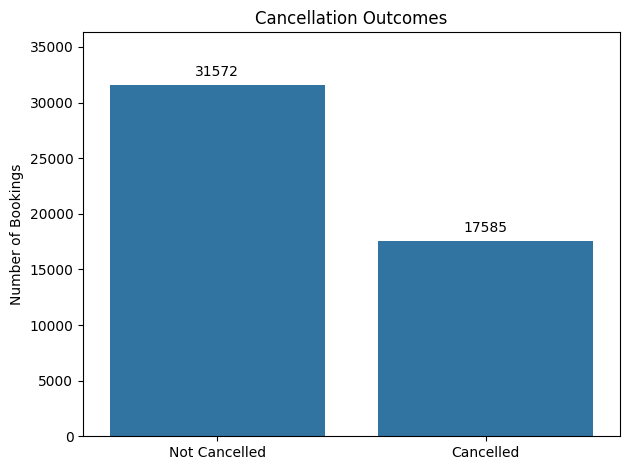

In [110]:
# Cancellation distribution
ax = sns.countplot(x=y_train, order=[0, 1])
ax.set_xticks([0, 1], ['Not Cancelled', 'Cancelled'])
ax.bar_label(ax.containers[0], fmt='%.0f', padding=4)
plt.ylim(0, y_train.value_counts().max() * 1.15)
plt.title("Cancellation Outcomes")
plt.xlabel("")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

### Class Distribution by Hotel

Reuse the hotel summary from EDA.


In [111]:
# Show both classes using the existing hotel totals
hotel_classes = hotel_summary[['bookings', 'cancellations']].copy()
hotel_classes['not_cancelled'] = hotel_classes['bookings'] - hotel_classes['cancellations']
hotel_classes['cancelled_pct'] = hotel_summary['cancellation_rate_pct']
hotel_classes[['not_cancelled', 'cancellations', 'bookings', 'cancelled_pct']].round(2)

,not_cancelled,cancellations,bookings,cancelled_pct
hotel,,,,
City Hotel,18448,13175,31623,41.66
Resort Hotel,13124,4410,17534,25.15


### Class Distribution by Market Segment

Reuse the segment summary, keeping each hotel separate.

In [112]:
# Reuse the existing market-segment counts and rates
segment_classes = segment_summary[['bookings', 'cancellations']].copy()
segment_classes['not_cancelled'] = segment_classes['bookings'] - segment_classes['cancellations']
segment_classes['cancelled_pct'] = segment_summary['cancellation_rate_pct']
segment_classes[['not_cancelled', 'cancellations', 'bookings', 'cancelled_pct']].round(2)

not_cancelled  cancellations  bookings  \
market_segment hotel                                                  
Aviation       City Hotel               49             15        64   
Complementary  City Hotel              233             28       261   
               Resort Hotel             69              8        77   
Corporate      City Hotel             1209            316      1525   
               Resort Hotel           1031            156      1187   
Direct         City Hotel             1839            370      2209   
               Resort Hotel           2474            318      2792   
Groups         City Hotel             2457           4906      7363   
               Resort Hotel           1506           1520      3026   
Offline TA/TO  City Hotel             4831           3967      8798   
               Resort Hotel           3393            587      3980   
Online TA      City Hotel             7830           3571     11401   
               Resort Hotel           4651           1821      6472   
Undefined      City Hotel                0              2         2   

                             cancelled_pct  
market_segment hotel                        
Aviation       City Hotel            23.44  
Complementary  City Hotel            10.73  
               Resort Hotel          10.39  
Corporate      City Hotel            20.72  
               Resort Hotel          13.14  
Direct         City Hotel            16.75  
               Resort Hotel          11.39  
Groups         City Hotel            66.63  
               Resort Hotel          50.23  
Offline TA/TO  City Hotel            45.09  
               Resort Hotel          14.75  
Online TA      City Hotel            31.32  
               Resort Hotel          28.14  
Undefined      City Hotel           100.00

In [113]:
# Check that the reused EDA counts still match the final labels
if (class_summary['bookings'].sum() == len(y_train)
    and hotel_classes['cancellations'].sum() == y_train.sum()
    and segment_classes['cancellations'].sum() == y_train.sum()):
    print('Class counts match the final training labels')
else:
    raise ValueError('Check whether bookings or labels changed after EDA')

Class counts match the final training labels


### Class Distribution Findings

- Training has 31,572 non-cancelled bookings (64.23%) and 17,585 cancelled bookings (35.77%).
- Non-cancellation is the majority class, but both classes have many examples.
- The cancellation rate is 41.66% for City Hotel and 25.15% for Resort Hotel.
- Market-segment rates differ.
- Always predicting the majority class gives 64.23% training accuracy. This is just a reference.

## Class Imbalance Handling

I kept the original training distribution: 64.23% not cancelled and 35.77% cancelled.

- I did not oversample or undersample the bookings.
- I will start Logistic Regression without class weighting (`class_weight=None`).

Both classes have enough examples to start with. Since I need cancellation probabilities, I kept the natural distribution instead of making the class counts equal. Balancing can change the probability estimates, so I will check calibration using validation data.

I did not change any data in this stage. Keeping the natural distribution does not guarantee calibrated probabilities; I still need to evaluate them.

Next, I will combine preprocessing and Logistic Regression in one pipeline and fit it on training data only.
